<a href="https://colab.research.google.com/github/Sushmabt680/ADA/blob/main/np_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# %% [CELL 1] Imports and settings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

CFG = dict(
    n_nodes   = 100,          # number of sensor nodes
    area      = 100.0,        # network is area x area metres
    bs        = (50.0, 175.0),# base station position (outside the field)
    E0        = 0.5,          # initial energy per node (J)
    k         = 4000,         # packet size (bits)
    rounds    = 3000,         # max simulation rounds
    p         = 0.05,         # desired fraction of cluster heads (5%)
    E_elec    = 50e-9,        # J/bit  (TX/RX electronics)
    E_fs      = 10e-12,       # J/bit/m^2  (free space)
    E_mp      = 0.0013e-12,   # J/bit/m^4  (multipath)
    E_da      = 5e-9,         # J/bit/signal (data aggregation)
)
CFG["d0"] = np.sqrt(CFG["E_fs"] / CFG["E_mp"])   # distance threshold
print("Threshold distance d0 = %.1f m" % CFG["d0"])

Threshold distance d0 = 87.7 m


In [2]:
# %% [CELL 2] Energy model (first-order radio model)
def e_tx(k, d, c=CFG):
    """Transmission energy for k bits over distance d (vectorised)."""
    d = np.asarray(d, dtype=float)
    return np.where(d < c["d0"],
                    k * c["E_elec"] + k * c["E_fs"] * d**2,
                    k * c["E_elec"] + k * c["E_mp"] * d**4)

def e_rx(k, c=CFG):
    """Reception energy for k bits."""
    return k * c["E_elec"]

In [3]:
# %% [CELL 3] Network creation
def create_network(seed, c=CFG):
    rng = np.random.default_rng(seed)
    x = rng.uniform(0, c["area"], c["n_nodes"])
    y = rng.uniform(0, c["area"], c["n_nodes"])
    E = np.full(c["n_nodes"], c["E0"])
    d_bs = np.hypot(x - c["bs"][0], y - c["bs"][1])
    return x, y, E, d_bs

def metrics_row(rnd, E, alive_prev, delivered_readings, bs_msgs, ch_count):
    return dict(round=rnd,
                alive=int(np.sum(E > 0)),
                residual=float(E.sum()),
                readings=delivered_readings,
                bs_msgs=bs_msgs,
                n_ch=ch_count)


In [4]:
# %% [CELL 4] Algorithm 1: Direct transmission (baseline)
def run_direct(seed, c=CFG):
    x, y, E, d_bs = create_network(seed, c)
    log = []
    for r in range(1, c["rounds"] + 1):
        alive = E > 0
        if not alive.any():
            break
        cost = e_tx(c["k"], d_bs)
        E[alive] -= cost[alive]
        E[E < 0] = 0
        n = int(alive.sum())
        log.append(metrics_row(r, E, alive, n, n, 0))
    return pd.DataFrame(log)

In [5]:
# %% [CELL 5] Algorithms 2 & 3: LEACH and Proposed Energy-Aware LEACH
def run_cluster(seed, mode="leach", c=CFG, return_snapshot_at=None):
    """
    mode = 'leach'   : classic LEACH probabilistic CH election
    mode = 'proposed': energy-aware CH election
         score = w1 * (E_res/E0) + w2 * (1 - d_bs/d_bs_max)
         - exactly k_ch = round(p * alive) CHs chosen by highest score
         - nodes that served as CH recently are excluded (rotation)
    """
    x, y, E, d_bs = create_network(seed, c)
    n = c["n_nodes"]
    p, k = c["p"], c["k"]
    period = int(round(1 / p))
    last_ch = np.full(n, -10**9)      # round in which node last was CH
    G = np.ones(n, dtype=bool)        # LEACH eligibility set
    log, snapshot = [], None
    w1, w2 = 0.7, 0.3

    for r in range(1, c["rounds"] + 1):
        alive = E > 0
        n_alive = int(alive.sum())
        if n_alive == 0:
            break

        # ------------- 1. Cluster-head election -------------
        if mode == "leach":
            if (r - 1) % period == 0:
                G[:] = True
            T = p / (1 - p * ((r - 1) % period))
            rnd_vals = np.random.default_rng(seed * 100000 + r).random(n)
            is_ch = alive & G & (rnd_vals < T)
            G[is_ch] = False
        else:
            k_ch = max(1, int(round(p * n_alive)))
            eligible = alive & ((r - last_ch) > period)
            if eligible.sum() < k_ch:              # fallback: relax rotation
                eligible = alive.copy()
            score = w1 * (E / c["E0"]) + w2 * (1 - d_bs / d_bs.max())
            score = np.where(eligible, score, -np.inf)
            top = np.argsort(score)[::-1][:k_ch]
            is_ch = np.zeros(n, dtype=bool)
            is_ch[top] = True
            is_ch &= eligible
            last_ch[is_ch] = r

        ch_idx = np.where(is_ch)[0]
        # if no CH elected, nodes send directly to BS this round
        if len(ch_idx) == 0:
            cost = e_tx(k, d_bs)
            E[alive] -= cost[alive]
            E[E < 0] = 0
            log.append(metrics_row(r, E, alive, n_alive, n_alive, 0))
            continue

        # ------------- 2. Cluster formation -------------
        member_idx = np.where(alive & ~is_ch)[0]
        dist = np.hypot(x[member_idx, None] - x[None, ch_idx],
                        y[member_idx, None] - y[None, ch_idx])
        nearest = dist.argmin(axis=1)
        d_member = dist[np.arange(len(member_idx)), nearest]
        assign = ch_idx[nearest]                    # CH id of each member

        if return_snapshot_at == r:
            snapshot = dict(x=x.copy(), y=y.copy(), alive=alive.copy(),
                            ch=ch_idx.copy(), member=member_idx.copy(),
                            assign=assign.copy(), bs=c["bs"])

        # ------------- 3. Members send to CH -------------
        E[member_idx] -= e_tx(k, d_member)

        # ------------- 4. CH receive + aggregate + send to BS -------------
        for j, ch in enumerate(ch_idx):
            n_mem = int(np.sum(assign == ch))
            E[ch] -= n_mem * e_rx(k)                    # receive
            E[ch] -= (n_mem + 1) * k * c["E_da"]        # aggregate
            E[ch] -= float(e_tx(k, d_bs[ch]))           # forward to BS
        E[E < 0] = 0

        log.append(metrics_row(r, E, alive, n_alive, len(ch_idx), len(ch_idx)))

    df = pd.DataFrame(log)
    return (df, snapshot) if return_snapshot_at else df




In [7]:

# %% [CELL 6] Lifetime metrics (FND / HND / LND)
def lifetime_metrics(df, c=CFG):
    n = c["n_nodes"]
    alive = df["alive"].values
    rounds = df["round"].values
    def first_round(cond):
        idx = np.where(cond)[0]
        return int(rounds[idx[0]]) if len(idx) else int(rounds[-1])
    fnd = first_round(alive < n)
    hnd = first_round(alive <= n // 2)
    lnd = first_round(alive == 0)
    total_energy = c["n_nodes"] * c["E0"]
    return dict(FND=fnd, HND=hnd, LND=lnd,
                total_readings=int(df["readings"].sum()),
                energy_used_J=round(total_energy - df["residual"].iloc[-1], 4))

In [8]:
# %% [CELL 7] Run all three algorithms (single seed) + comparison table
SEED = 42
res = {
    "Direct":          run_direct(SEED),
    "LEACH":           run_cluster(SEED, "leach"),
    "Proposed E-LEACH": run_cluster(SEED, "proposed"),
}
table = pd.DataFrame({name: lifetime_metrics(df) for name, df in res.items()}).T
print(table)

                    FND    HND     LND  total_readings  energy_used_J
Direct             96.0  322.0  1137.0         42561.0           50.0
LEACH             725.0  895.0  1217.0         92312.0           50.0
Proposed E-LEACH  673.0  938.0  1071.0         91367.0           50.0


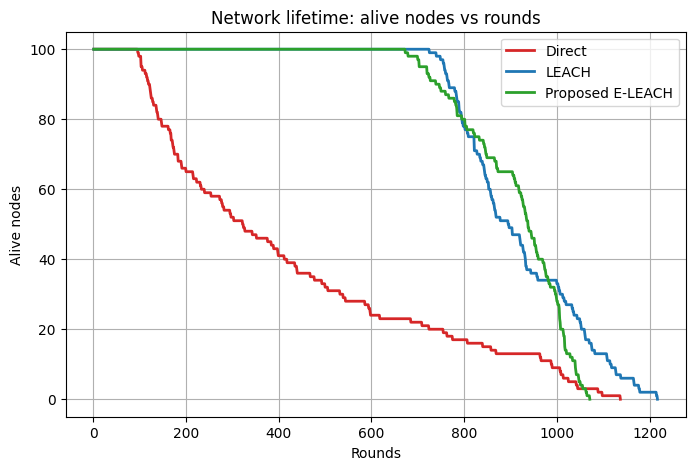

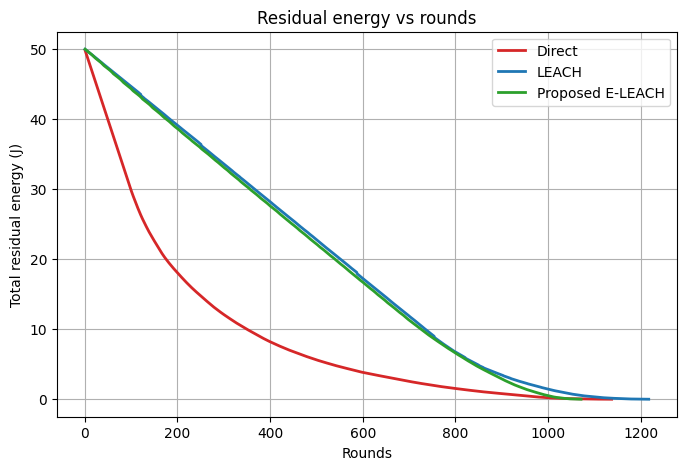

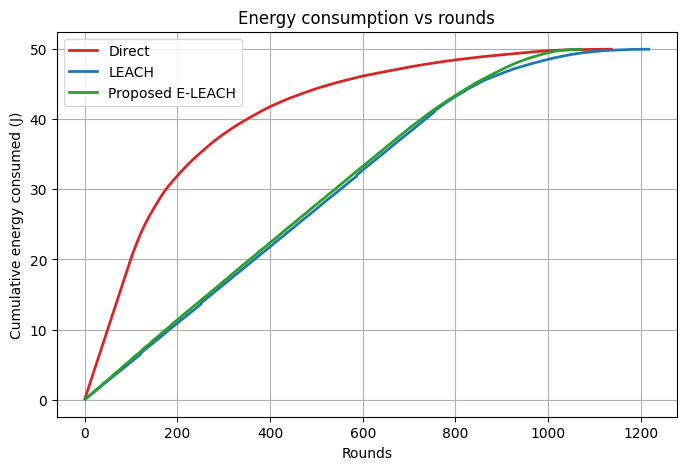

In [9]:
# %% [CELL 8] Graphs: alive nodes, residual energy, energy consumed
colors = {"Direct": "tab:red", "LEACH": "tab:blue", "Proposed E-LEACH": "tab:green"}

plt.figure()
for name, df in res.items():
    plt.plot(df["round"], df["alive"], label=name, color=colors[name], lw=2)
plt.xlabel("Rounds"); plt.ylabel("Alive nodes")
plt.title("Network lifetime: alive nodes vs rounds"); plt.legend(); plt.show()

plt.figure()
for name, df in res.items():
    plt.plot(df["round"], df["residual"], label=name, color=colors[name], lw=2)
plt.xlabel("Rounds"); plt.ylabel("Total residual energy (J)")
plt.title("Residual energy vs rounds"); plt.legend(); plt.show()

plt.figure()
for name, df in res.items():
    consumed = CFG["n_nodes"] * CFG["E0"] - df["residual"]
    plt.plot(df["round"], consumed, label=name, color=colors[name], lw=2)
plt.xlabel("Rounds"); plt.ylabel("Cumulative energy consumed (J)")
plt.title("Energy consumption vs rounds"); plt.legend(); plt.show()


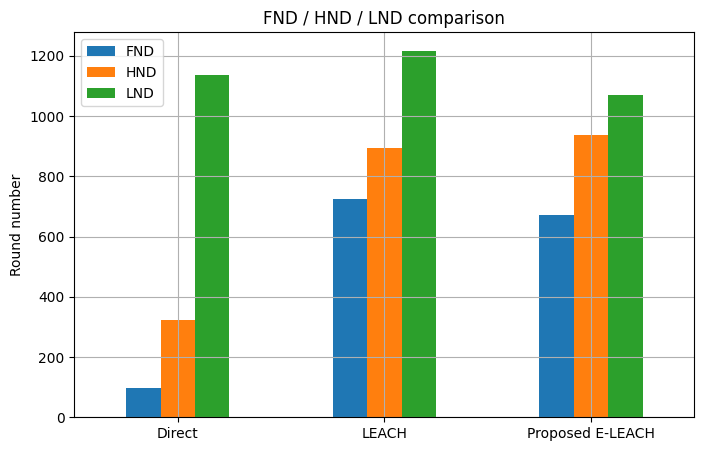

In [10]:
# %% [CELL 9] Bar chart: FND / HND / LND
lt = table[["FND", "HND", "LND"]]
lt.plot(kind="bar", figsize=(8, 5), rot=0)
plt.ylabel("Round number"); plt.title("FND / HND / LND comparison"); plt.show()


In [12]:
# %% [CELL 10] Energy per round and rounds-to-first-death improvement
def pct_gain(new, old):
    return 100.0 * (new - old) / old

for base in ["Direct", "LEACH"]:
    for m in ["FND", "HND", "LND"]:
        g = pct_gain(table.loc["Proposed E-LEACH", m], table.loc[base, m])
        print(f"{m}: Proposed vs {base}: {g:+.1f}%")

# Energy per delivered reading (fair efficiency measure)
table["J_per_reading"] = table["energy_used_J"] / table["total_readings"]
print("\nEnergy per delivered sensor reading (J):")
print(table["J_per_reading"])

FND: Proposed vs Direct: +601.0%
HND: Proposed vs Direct: +191.3%
LND: Proposed vs Direct: -5.8%
FND: Proposed vs LEACH: -7.2%
HND: Proposed vs LEACH: +4.8%
LND: Proposed vs LEACH: -12.0%

Energy per delivered sensor reading (J):
Direct              0.001175
LEACH               0.000542
Proposed E-LEACH    0.000547
Name: J_per_reading, dtype: float64


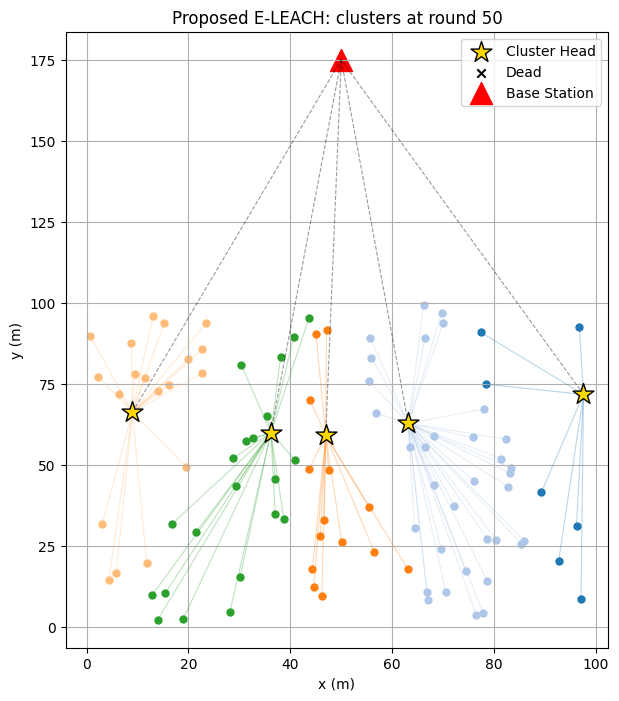

In [13]:
# %% [CELL 11] Network visualisation (clusters in one round)
_, snap = run_cluster(SEED, "proposed", return_snapshot_at=50)
if snap:
    plt.figure(figsize=(7, 8))
    cmap = plt.cm.tab20
    for i, ch in enumerate(snap["ch"]):
        mem = snap["member"][snap["assign"] == ch]
        plt.scatter(snap["x"][mem], snap["y"][mem], s=25, color=cmap(i % 20))
        for m in mem:
            plt.plot([snap["x"][m], snap["x"][ch]], [snap["y"][m], snap["y"][ch]],
                     color=cmap(i % 20), alpha=0.3, lw=0.8)
        plt.plot([snap["x"][ch], snap["bs"][0]], [snap["y"][ch], snap["bs"][1]],
                 "k--", alpha=0.4, lw=0.8)
    plt.scatter(snap["x"][snap["ch"]], snap["y"][snap["ch"]], marker="*", s=250,
                color="gold", edgecolor="k", label="Cluster Head", zorder=5)
    dead = ~snap["alive"]
    plt.scatter(snap["x"][dead], snap["y"][dead], marker="x", color="black", label="Dead")
    plt.scatter(*snap["bs"], marker="^", s=250, color="red", label="Base Station")
    plt.legend(); plt.title("Proposed E-LEACH: clusters at round 50")
    plt.xlabel("x (m)"); plt.ylabel("y (m)"); plt.show()


                    FND          HND           LND       energy_used_J     
                   mean   std   mean   std    mean   std          mean  std
algorithm                                                                  
Direct             91.7   3.5  324.7  50.6  1138.3  25.6          50.0  0.0
LEACH             710.6  19.0  896.9  17.4  1211.5  32.1          50.0  0.0
Proposed E-LEACH  703.2  33.5  952.4  15.3  1062.1  15.6          50.0  0.0


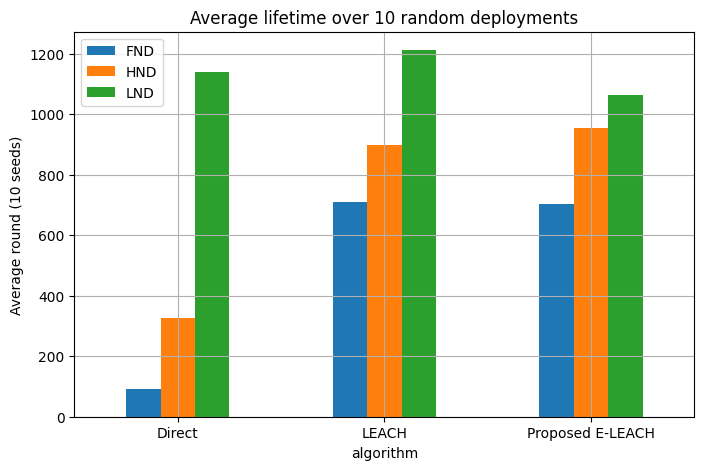

In [14]:
# %% [CELL 12] Multiple random seeds (robust, fair comparison)
def multi_seed(seeds):
    rows = []
    for s in seeds:
        for name, fn in [("Direct", lambda s: run_direct(s)),
                         ("LEACH", lambda s: run_cluster(s, "leach")),
                         ("Proposed E-LEACH", lambda s: run_cluster(s, "proposed"))]:
            m = lifetime_metrics(fn(s))
            m.update(algorithm=name, seed=s)
            rows.append(m)
    return pd.DataFrame(rows)

runs = multi_seed(range(1, 11))
summary = runs.groupby("algorithm")[["FND", "HND", "LND", "energy_used_J"]].agg(["mean", "std"]).round(1)
print(summary)

runs.groupby("algorithm")[["FND", "HND", "LND"]].mean().plot(kind="bar", figsize=(8, 5), rot=0)
plt.ylabel("Average round (10 seeds)"); plt.title("Average lifetime over 10 random deployments")
plt.show()


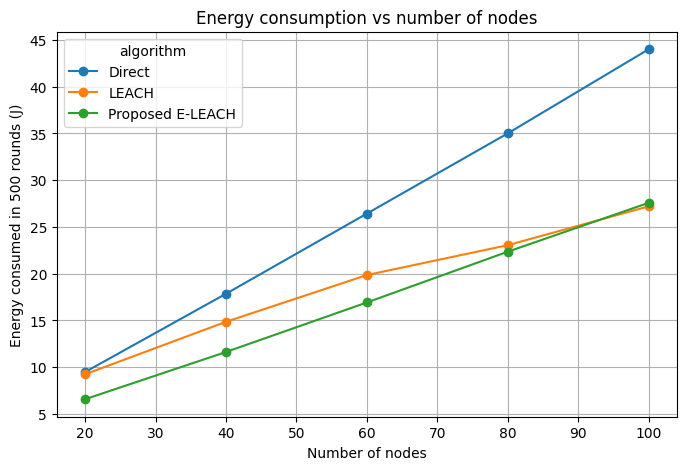

algorithm  Direct  LEACH  Proposed E-LEACH
nodes                                     
20           9.48   9.24              6.58
40          17.85  14.86             11.63
60          26.43  19.86             16.92
80          35.01  23.05             22.35
100         44.00  27.20             27.58
algorithm    Direct  LEACH  Proposed E-LEACH
packet_bits                                 
2000            180   1433              1397
4000             90    710               695
8000             45    341               333


In [15]:
# %% [CELL 13] Scalability: vary number of nodes (like the paper graphs)
sizes = [20, 40, 60, 80, 100]
rows = []
for n in sizes:
    c2 = dict(CFG); c2["n_nodes"] = n
    for name, fn in [("Direct", lambda: run_direct(7, c2)),
                     ("LEACH", lambda: run_cluster(7, "leach", c2)),
                     ("Proposed E-LEACH", lambda: run_cluster(7, "proposed", c2))]:
        df = fn()
        # energy used in the first 500 rounds (same window for all)
        sub = df[df["round"] <= 500]
        used = n * c2["E0"] - sub["residual"].iloc[-1]
        rows.append(dict(nodes=n, algorithm=name, energy_J=used))
sc = pd.DataFrame(rows).pivot(index="nodes", columns="algorithm", values="energy_J")
sc.plot(marker="o", figsize=(8, 5))
plt.xlabel("Number of nodes"); plt.ylabel("Energy consumed in 500 rounds (J)")
plt.title("Energy consumption vs number of nodes"); plt.show()
print(sc.round(2))


# %% [CELL 14] Sensitivity: packet size (optional extra analysis)
rows = []
for k in [2000, 4000, 8000]:
    c3 = dict(CFG); c3["k"] = k
    for name, fn in [("Direct", lambda: run_direct(7, c3)),
                     ("LEACH", lambda: run_cluster(7, "leach", c3)),
                     ("Proposed E-LEACH", lambda: run_cluster(7, "proposed", c3))]:
        m = lifetime_metrics(fn(), c3)
        rows.append(dict(packet_bits=k, algorithm=name, FND=m["FND"], LND=m["LND"]))
print(pd.DataFrame(rows).pivot(index="packet_bits", columns="algorithm", values="FND"))



In [16]:
# %% [CELL 15] Save results to CSV (download from Colab file panel)
table.to_csv("simulation_summary.csv")
runs.to_csv("multi_seed_results.csv", index=False)
for name, df in res.items():
    df.to_csv(f"rounds_{name.replace(' ', '_')}.csv", index=False)
print("Saved CSV files. Open the folder icon on the left in Colab to download.")


Saved CSV files. Open the folder icon on the left in Colab to download.


In [18]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 88.6 MB/s eta 0:00:00


2026-10-23 16:48:27.933 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-23 16:48:27.939 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-23 16:48:28.228 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 16:48:28.233 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 16:48:28.574 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-10-23 16:48:28.577 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 16:48:28.580 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running 

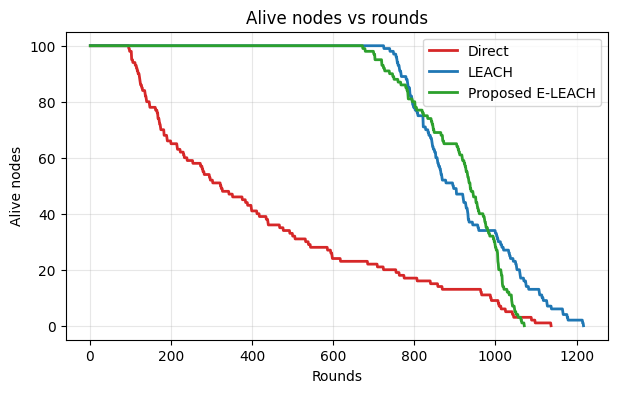

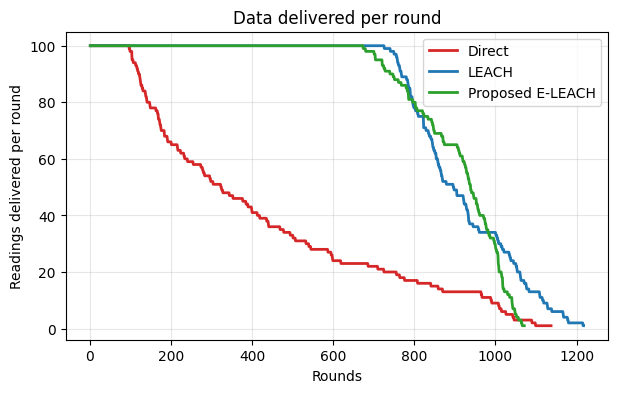

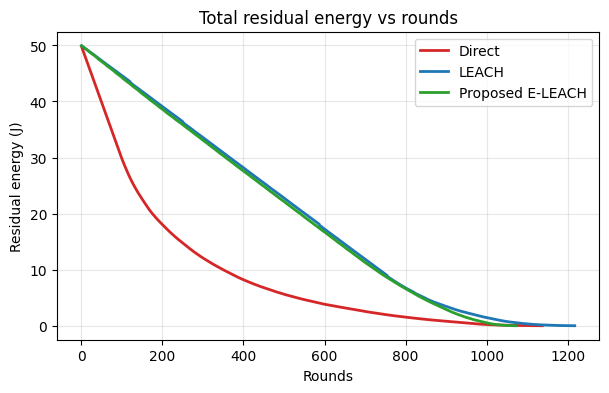

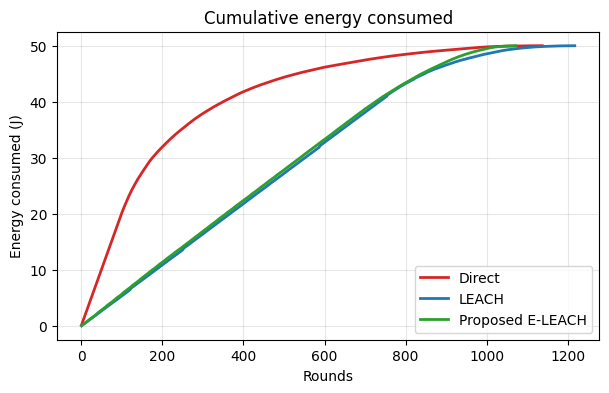

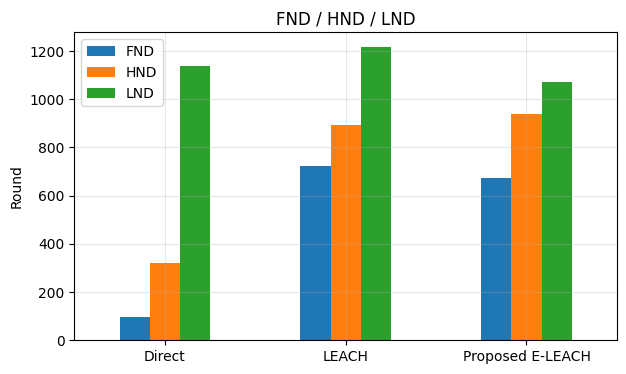

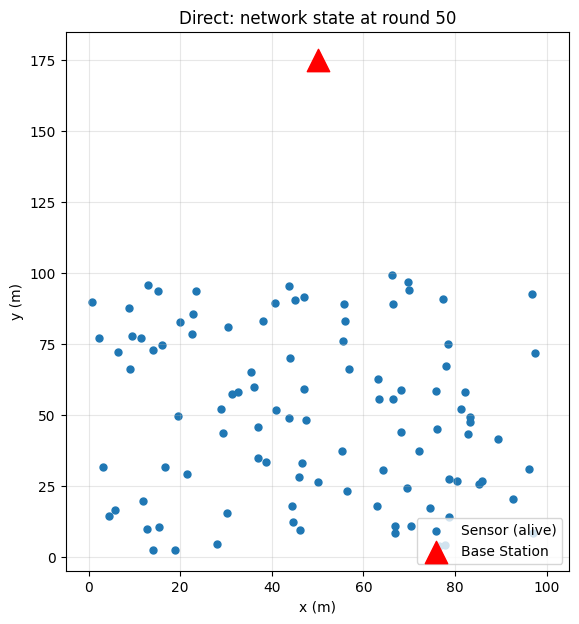

In [19]:
# =====================================================================
# Efficient Energy Consumption in Wireless Sensor Networks (WSN)
# Streamlit dashboard: Direct vs LEACH vs Proposed Energy-Aware LEACH
# Run:  pip install streamlit numpy pandas matplotlib
#       streamlit run app.py
# =====================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

# --------------------------------------------------------------------
# 1. ENERGY MODEL (first-order radio model)
# --------------------------------------------------------------------
def make_cfg(n_nodes, area, E0, k, rounds, p, bs_y):
    c = dict(n_nodes=n_nodes, area=float(area), E0=E0, k=k, rounds=rounds, p=p,
             bs=(area / 2.0, float(bs_y)),
             E_elec=50e-9, E_fs=10e-12, E_mp=0.0013e-12, E_da=5e-9)
    c["d0"] = np.sqrt(c["E_fs"] / c["E_mp"])
    return c

def e_tx(k, d, c):
    d = np.asarray(d, dtype=float)
    return np.where(d < c["d0"],
                    k * c["E_elec"] + k * c["E_fs"] * d ** 2,
                    k * c["E_elec"] + k * c["E_mp"] * d ** 4)

def e_rx(k, c):
    return k * c["E_elec"]

# --------------------------------------------------------------------
# 2. NETWORK + ALGORITHMS
# --------------------------------------------------------------------
def create_network(seed, c):
    rng = np.random.default_rng(seed)
    x = rng.uniform(0, c["area"], c["n_nodes"])
    y = rng.uniform(0, c["area"], c["n_nodes"])
    E = np.full(c["n_nodes"], c["E0"])
    d_bs = np.hypot(x - c["bs"][0], y - c["bs"][1])
    return x, y, E, d_bs

def row(rnd, E, readings, bs_msgs, n_ch):
    return dict(round=rnd, alive=int(np.sum(E > 0)), residual=float(E.sum()),
                readings=readings, bs_msgs=bs_msgs, n_ch=n_ch)

def run_direct(seed, c):
    x, y, E, d_bs = create_network(seed, c)
    log = []
    for r in range(1, c["rounds"] + 1):
        alive = E > 0
        if not alive.any():
            break
        E[alive] -= e_tx(c["k"], d_bs, c)[alive]
        E[E < 0] = 0
        n = int(alive.sum())
        log.append(row(r, E, n, n, 0))
    return pd.DataFrame(log), None

def run_cluster(seed, c, mode="leach", w1=0.7, w2=0.3, snapshot_at=None):
    """mode: 'leach' (probabilistic) or 'proposed' (energy-aware)."""
    x, y, E, d_bs = create_network(seed, c)
    n, p, k = c["n_nodes"], c["p"], c["k"]
    period = max(1, int(round(1 / p)))
    last_ch = np.full(n, -10 ** 9)
    G = np.ones(n, dtype=bool)
    log, snap = [], None

    for r in range(1, c["rounds"] + 1):
        alive = E > 0
        n_alive = int(alive.sum())
        if n_alive == 0:
            break

        # ---- cluster-head election ----
        if mode == "leach":
            if (r - 1) % period == 0:
                G[:] = True
            T = p / (1 - p * ((r - 1) % period))
            rv = np.random.default_rng(seed * 100000 + r).random(n)
            is_ch = alive & G & (rv < T)
            G[is_ch] = False
        else:
            k_ch = max(1, int(round(p * n_alive)))
            eligible = alive & ((r - last_ch) > period)
            if eligible.sum() < k_ch:
                eligible = alive.copy()
            score = w1 * (E / c["E0"]) + w2 * (1 - d_bs / d_bs.max())
            score = np.where(eligible, score, -np.inf)
            top = np.argsort(score)[::-1][:k_ch]
            is_ch = np.zeros(n, dtype=bool)
            is_ch[top] = True
            is_ch &= eligible
            last_ch[is_ch] = r

        ch_idx = np.where(is_ch)[0]
        if len(ch_idx) == 0:                      # no CH -> direct this round
            E[alive] -= e_tx(k, d_bs, c)[alive]
            E[E < 0] = 0
            log.append(row(r, E, n_alive, n_alive, 0))
            continue

        # ---- cluster formation ----
        member_idx = np.where(alive & ~is_ch)[0]
        dist = np.hypot(x[member_idx, None] - x[None, ch_idx],
                        y[member_idx, None] - y[None, ch_idx])
        nearest = dist.argmin(axis=1)
        d_member = dist[np.arange(len(member_idx)), nearest]
        assign = ch_idx[nearest]

        if snapshot_at == r:
            snap = dict(x=x.copy(), y=y.copy(), E=E.copy(), alive=alive.copy(),
                        ch=ch_idx.copy(), member=member_idx.copy(),
                        assign=assign.copy(), round=r)

        # ---- energy accounting ----
        E[member_idx] -= e_tx(k, d_member, c)
        for ch in ch_idx:
            n_mem = int(np.sum(assign == ch))
            E[ch] -= n_mem * e_rx(k, c)                  # receive
            E[ch] -= (n_mem + 1) * k * c["E_da"]         # aggregate
            E[ch] -= float(e_tx(k, d_bs[ch], c))         # forward to BS
        E[E < 0] = 0
        log.append(row(r, E, n_alive, len(ch_idx), len(ch_idx)))

    return pd.DataFrame(log), snap

def get_snapshot(seed, c, mode, w1, w2, rnd):
    if mode == "Direct":
        x, y, E, d_bs = create_network(seed, c)
        return dict(x=x, y=y, alive=np.ones(len(x), bool), ch=np.array([], int),
                    member=np.arange(len(x)), assign=np.array([], int), round=rnd)
    m = "leach" if mode == "LEACH" else "proposed"
    _, snap = run_cluster(seed, c, m, w1, w2, snapshot_at=rnd)
    return snap

# --------------------------------------------------------------------
# 3. METRICS
# --------------------------------------------------------------------
def lifetime(df, c):
    n, rounds, alive = c["n_nodes"], df["round"].values, df["alive"].values
    def first(cond):
        i = np.where(cond)[0]
        return int(rounds[i[0]]) if len(i) else int(rounds[-1])
    fnd, hnd, lnd = first(alive < n), first(alive <= n // 2), first(alive == 0)
    used = c["n_nodes"] * c["E0"] - df["residual"].iloc[-1]
    total_read = int(df["readings"].sum())
    return dict(FND=fnd, HND=hnd, LND=lnd,
                energy_used_J=round(used, 4),
                readings_delivered=total_read,
                J_per_reading=used / max(total_read, 1),
                msgs_to_BS=int(df["bs_msgs"].sum()))

@st.cache_data(show_spinner=False)
def run_all(seed, cfg_tuple, w1, w2):
    c = make_cfg(*cfg_tuple)
    out = {}
    out["Direct"], _ = run_direct(seed, c)
    out["LEACH"], _ = run_cluster(seed, c, "leach")
    out["Proposed E-LEACH"], _ = run_cluster(seed, c, "proposed", w1, w2)
    return out

@st.cache_data(show_spinner=False)
def run_multi(seeds, cfg_tuple, w1, w2):
    c = make_cfg(*cfg_tuple)
    rows = []
    for s in seeds:
        for name, fn in [("Direct", lambda s: run_direct(s, c)[0]),
                         ("LEACH", lambda s: run_cluster(s, c, "leach")[0]),
                         ("Proposed E-LEACH", lambda s: run_cluster(s, c, "proposed", w1, w2)[0])]:
            m = lifetime(fn(s), c)
            m.update(algorithm=name, seed=s)
            rows.append(m)
    return pd.DataFrame(rows)

# --------------------------------------------------------------------
# 4. PLOT HELPERS
# --------------------------------------------------------------------
COLORS = {"Direct": "tab:red", "LEACH": "tab:blue", "Proposed E-LEACH": "tab:green"}

def line_plot(res, col, ylabel, title, transform=None):
    fig, ax = plt.subplots(figsize=(7, 4))
    for name, df in res.items():
        y = df[col] if transform is None else transform(df[col])
        ax.plot(df["round"], y, label=name, color=COLORS[name], lw=2)
    ax.set_xlabel("Rounds"); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.grid(alpha=0.3); ax.legend()
    return fig

def network_plot(snap, c, title):
    fig, ax = plt.subplots(figsize=(6.5, 7))
    cmap = plt.cm.tab20
    alive, x, y = snap["alive"], snap["x"], snap["y"]
    if len(snap["ch"]) == 0:
        ax.scatter(x[alive], y[alive], s=25, color="tab:blue", label="Sensor (alive)")
    for i, ch in enumerate(snap["ch"]):
        mem = snap["member"][snap["assign"] == ch]
        col = cmap(i % 20)
        ax.scatter(x[mem], y[mem], s=25, color=col)
        for m in mem:
            ax.plot([x[m], x[ch]], [y[m], y[ch]], color=col, alpha=0.35, lw=0.8)
        ax.plot([x[ch], c["bs"][0]], [y[ch], c["bs"][1]], "k--", alpha=0.35, lw=0.8)
    if len(snap["ch"]):
        ax.scatter(x[snap["ch"]], y[snap["ch"]], marker="*", s=260, color="gold",
                   edgecolor="k", zorder=5, label="Cluster Head")
    dead = ~alive
    if dead.any():
        ax.scatter(x[dead], y[dead], marker="x", color="black", label="Dead node")
    ax.scatter(*c["bs"], marker="^", s=260, color="red", label="Base Station", zorder=6)
    ax.set_xlim(-5, c["area"] + 5)
    ax.set_ylim(-5, max(c["area"], c["bs"][1]) + 10)
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_title(title)
    ax.legend(loc="lower right"); ax.grid(alpha=0.3)
    return fig

# --------------------------------------------------------------------
# 5. STREAMLIT UI
# --------------------------------------------------------------------
def main():
    st.set_page_config(page_title="WSN Energy Simulator", page_icon="🔋", layout="wide")
    st.title("🔋 Energy-Efficient Wireless Sensor Network Simulator")
    st.caption("Compare Direct Transmission, LEACH and a Proposed Energy-Aware "
               "Clustering protocol under identical conditions.")

    # ---------- sidebar ----------
    st.sidebar.header("⚙️ Network configuration")
    n_nodes = st.sidebar.slider("Number of sensor nodes", 20, 300, 100, 10)
    area = st.sidebar.slider("Field size (m x m)", 50, 300, 100, 10)
    bs_y = st.sidebar.slider("Base station y-position (m)", 0, 400, 175, 5,
                             help="x is fixed at the field centre. Values above the field "
                                  "size place the BS outside the field.")
    E0 = st.sidebar.number_input("Initial energy per node (J)", 0.1, 5.0, 0.5, 0.1)
    k = st.sidebar.select_slider("Packet size (bits)", [1000, 2000, 4000, 8000, 16000], 4000)
    rounds = st.sidebar.slider("Max rounds", 500, 5000, 3000, 250)
    p = st.sidebar.slider("Cluster-head fraction (p)", 0.02, 0.20, 0.05, 0.01)
    seed = st.sidebar.number_input("Random seed", 0, 9999, 42, 1)

    st.sidebar.header("🧠 Proposed algorithm weights")
    w1 = st.sidebar.slider("Weight: residual energy", 0.0, 1.0, 0.7, 0.05)
    w2 = round(1.0 - w1, 2)
    st.sidebar.write(f"Weight: distance to BS = **{w2}**")

    cfg_tuple = (n_nodes, area, E0, k, rounds, p, bs_y)
    c = make_cfg(*cfg_tuple)

    run = st.sidebar.button("▶️ Run simulation", type="primary", use_container_width=True)
    if run or "res" not in st.session_state:
        with st.spinner("Simulating..."):
            st.session_state["res"] = run_all(int(seed), cfg_tuple, w1, w2)
            st.session_state["cfg"] = c
            st.session_state["seed"] = int(seed)
            st.session_state["w"] = (w1, w2)
            st.session_state.pop("multi", None)

    res = st.session_state["res"]
    c = st.session_state["cfg"]
    seed_used = st.session_state["seed"]
    w1u, w2u = st.session_state["w"]

    table = pd.DataFrame({n: lifetime(df, c) for n, df in res.items()}).T

    tab1, tab2, tab3, tab4, tab5 = st.tabs(
        ["📊 Summary", "📈 Graphs", "🗺️ Network view", "🔁 Multi-seed test", "ℹ️ About / Method"])

    # ---------- Tab 1: summary ----------
    with tab1:
        total_E = c["n_nodes"] * c["E0"]
        a, b, d_ = st.columns(3)
        a.metric("Nodes", c["n_nodes"])
        b.metric("Total initial energy", f"{total_E:.1f} J")
        d_.metric("Threshold distance d0", f"{c['d0']:.1f} m")

        st.subheader("Lifetime and energy comparison")
        show = table.copy()
        show["J_per_reading"] = show["J_per_reading"].map(lambda v: f"{v:.6f}")
        show.columns = ["FND (round)", "HND (round)", "LND (round)", "Energy used (J)",
                        "Readings delivered", "Energy per reading (J)", "Messages to BS"]
        st.dataframe(show, use_container_width=True)

        st.subheader("Improvement of the proposed method")
        prop = table.loc["Proposed E-LEACH"]
        cols = st.columns(2)
        for col, base in zip(cols, ["Direct", "LEACH"]):
            with col:
                st.markdown(f"**vs {base}**")
                for m in ["FND", "HND", "LND"]:
                    gain = 100 * (prop[m] - table.loc[base, m]) / max(table.loc[base, m], 1)
                    st.metric(m, f"{int(prop[m])} rounds", f"{gain:+.1f}%")
                eff = 100 * (table.loc[base, "J_per_reading"] - prop["J_per_reading"]) \
                    / table.loc[base, "J_per_reading"]
                st.metric("Energy per delivered reading",
                          f"{prop['J_per_reading']:.6f} J", f"{eff:+.1f}% saved")

        st.info("Results come from the simulation you just ran. A single random "
                "deployment can be misleading, so confirm the trend in the "
                "**Multi-seed test** tab before drawing conclusions.")

        st.download_button("⬇️ Download summary CSV", table.to_csv().encode(),
                           "simulation_summary.csv", "text/csv")

    # ---------- Tab 2: graphs ----------
    with tab2:
        g1, g2 = st.columns(2)
        with g1:
            st.pyplot(line_plot(res, "alive", "Alive nodes", "Alive nodes vs rounds"))
            st.pyplot(line_plot(res, "readings", "Readings delivered per round",
                                "Data delivered per round"))
        with g2:
            st.pyplot(line_plot(res, "residual", "Residual energy (J)",
                                "Total residual energy vs rounds"))
            st.pyplot(line_plot(res, "residual", "Energy consumed (J)",
                                "Cumulative energy consumed",
                                transform=lambda s: c["n_nodes"] * c["E0"] - s))
        fig, ax = plt.subplots(figsize=(7, 4))
        table[["FND", "HND", "LND"]].plot(kind="bar", ax=ax, rot=0)
        ax.set_ylabel("Round"); ax.set_title("FND / HND / LND"); ax.grid(alpha=0.3)
        st.pyplot(fig)

        all_rounds = pd.concat(
            [df.assign(algorithm=n) for n, df in res.items()], ignore_index=True)
        st.download_button("⬇️ Download round-wise data (CSV)",
                           all_rounds.to_csv(index=False).encode(),
                           "round_wise_results.csv", "text/csv")

    # ---------- Tab 3: network view ----------
    with tab3:
        mode = st.radio("Algorithm", ["Direct", "LEACH", "Proposed E-LEACH"], horizontal=True)
        max_r = int(res[mode]["round"].max())
        rnd = st.slider("Round to inspect", 1, max_r, min(50, max_r))
        snap = get_snapshot(seed_used, c, mode, w1u, w2u, rnd)
        if snap is None:
            st.warning("No clusters were formed in this round (LEACH can elect zero cluster heads). Pick another round.")
        else:
            row_ = res[mode][res[mode]["round"] == rnd].iloc[0]
            m1, m2, m3 = st.columns(3)
            m1.metric("Alive nodes", int(row_["alive"]))
            m2.metric("Residual energy", f"{row_['residual']:.2f} J")
            m3.metric("Cluster heads this round", int(row_["n_ch"]))
            st.pyplot(network_plot(snap, c, f"{mode}: network state at round {rnd}"))

    # ---------- Tab 4: multi seed ----------
    with tab4:
        n_seeds = st.slider("Number of random deployments", 3, 20, 10)
        if st.button("Run multi-seed experiment"):
            with st.spinner("Running..."):
                st.session_state["multi"] = run_multi(
                    tuple(range(1, n_seeds + 1)), cfg_tuple, w1u, w2u)
        if "multi" in st.session_state:
            runs = st.session_state["multi"]
            summ = runs.groupby("algorithm")[["FND", "HND", "LND", "energy_used_J"]] \
                       .agg(["mean", "std"]).round(1)
            st.dataframe(summ, use_container_width=True)
            fig, ax = plt.subplots(figsize=(7, 4))
            runs.groupby("algorithm")[["FND", "HND", "LND"]].mean().plot(
                kind="bar", ax=ax, rot=0)
            ax.set_ylabel("Mean round"); ax.set_title("Mean lifetime over random deployments")
            ax.grid(alpha=0.3)
            st.pyplot(fig)
            st.download_button("⬇️ Download multi-seed CSV",
                               runs.to_csv(index=False).encode(),
                               "multi_seed_results.csv", "text/csv")
        else:
            st.write("Click the button to compare the algorithms over several "
                     "random node placements.")

    # ---------- Tab 5: about ----------
    with tab5:
        st.markdown(r"""
### Radio energy model (first-order)
- Transmit: $E_{TX}(k,d)=kE_{elec}+k\epsilon_{fs}d^2$ if $d<d_0$, else $kE_{elec}+k\epsilon_{mp}d^4$
- Receive: $E_{RX}(k)=kE_{elec}$
- Aggregation: $E_{DA}$ per bit per signal at the cluster head

### Algorithms
1. **Direct transmission** – every node sends straight to the base station.
2. **LEACH** – cluster heads are elected probabilistically; roles rotate every $1/p$ rounds.
3. **Proposed Energy-Aware LEACH** – cluster heads are chosen deterministically by
   `score = w1 * (E_res/E0) + w2 * (1 - d_BS/d_max)`; nodes that were recently CH are skipped.

### Metrics
- **FND / HND / LND**: round when the first / half / last node dies.
- **Energy per delivered reading** shows how efficiently each method turns energy into data.

### Assumptions and limitations
Idle listening, control messages, collisions, and sleep scheduling are not modelled.
Results depend on node placement, radio constants and parameters, so report them as
simulation findings, not universal claims.
""")

if __name__ == "__main__":
    main()

In [ ]:
import os, subprocess, socket, time

# 1. make sure app.py is there
if not os.path.exists("app.py"):
    from google.colab import files
    print("Upload app.py now...")
    files.upload()

# 2. start Streamlit, writing its output to a log file
log = open("streamlit.log", "w")
proc = subprocess.Popen(
    ["streamlit", "run", "app.py",
     "--server.port", "8501",
     "--server.address", "127.0.0.1",
     "--server.headless", "true"],
    stdout=log, stderr=log)

# 3. wait until the port is really open (up to 60 s)
for i in range(60):
    try:
        socket.create_connection(("127.0.0.1", 8501), timeout=1).close()
        print(f"Streamlit is up after {i+1}s")
        break
    except OSError:
        if proc.poll() is not None:      # Streamlit crashed
            break
        time.sleep(1)
else:
    print("Timed out waiting for Streamlit")

# 4. if it is not up, show why
try:
    socket.create_connection(("127.0.0.1", 8501), timeout=1).close()
except OSError:
    print("Streamlit did NOT start. Log:\n")
    print(open("streamlit.log").read())
    raise SystemExit

# 5. open the tunnel (use 127.0.0.1, not localhost)
!./cloudflared tunnel --url http://127.0.0.1:8501

Upload app.py now...


Saving app.py to app.py
Streamlit is up after 5s
2026-10-23T17:02:06Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-23T17:02:06Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-23T17:02:09Z INF +--------------------------------------------------------------------------------------------+
2026-10-23T17:02:09Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-23T17:02:09Z INF |  http